In [12]:
pacman::p_load(ggplot2,tidyverse,patchwork)

In [17]:
scaling_relationships=read.csv("merged_results.csv")

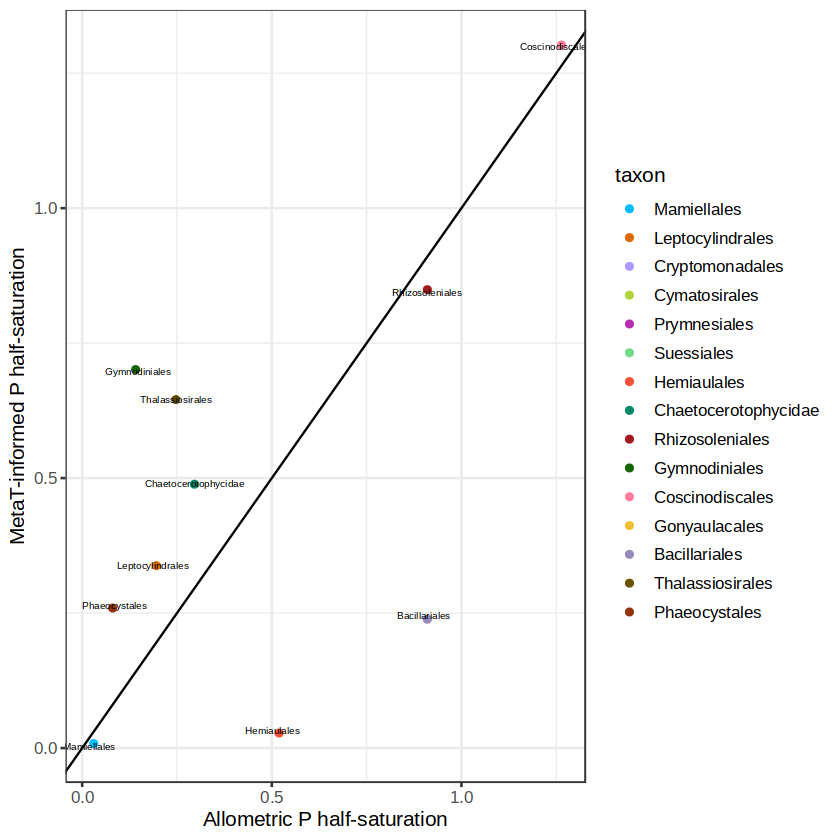

In [60]:
p_half_sat = ggplot(scaling_relationships %>%
                   dplyr::mutate(taxon=factor(taxon))%>%
                   dplyr::filter(metaT_p_half_sat>0))+
     geom_abline(aes(intercept=0,
                     slope=1))+
     geom_point(aes(x=half_sat_p,
                    y=metaT_p_half_sat,
                    color=taxon),show.legend = TRUE)+
     geom_text(aes(x=half_sat_p,
                   y=metaT_p_half_sat,
                   label=taxon),
               position="jitter",size=2) + 
     theme_bw(base_size=12) +
     scale_color_manual(values=c("#01bdff",
"#dd6800",
"#ae98ff",
"#b1d33c",
"#b92cb2",
"#71dc85",
"#f64f36",
"#008867",
"#a3191e",
"#136600",
"#ff7d9c",
"#f0c033",
"#9888bc",
"#695300",
"#93320e"),breaks=unique(scaling_relationships$taxon),drop = FALSE)+ 
    xlab("Allometric P half-saturation")+
    ylab("MetaT-informed P half-saturation")
p_half_sat

In [51]:
scaling_relationships

X,taxon,diameter,pft,parameter_a_gr,parameter_a_gr_denom,parameter_b_gr,parameter_a_no3,parameter_b_no3,parameter_a_no2,⋯,parameter_b_p,darwin_from_class,number_group,max_growth_rate,half_sat_n,half_sat_p,Taxon_x,metaT_p_half_sat,Taxon_y,metaT_n_half_sat
<int>,<chr>,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<chr>,<dbl>
0,Mamiellales,1.5,PicoEuk,1.284491e-05,86400,0.28,0.17,0.27,0.17,⋯,0.27,PicoEuk,3,1.3016103,0.4956242,0.03032054,Mamiellales,0.00834472,,NA
1,Leptocylindrales,15.0,Diatom,2.889699e-05,86400,-0.10,0.17,0.27,0.17,⋯,0.27,Diatom,7,1.1820589,3.2000184,0.19576583,Leptocylindrales,0.33780248,Leptocylindrales,3.695304e-01
2,Cryptomonadales,15.0,PicoEuk,1.284491e-05,86400,0.28,0.17,0.27,0.17,⋯,0.27,PicoEuk,3,9.0049435,3.2000184,0.19576583,,NA,Cryptomonadales,6.770453e-02
3,Cymatosirales,5.0,Diatom,2.889699e-05,86400,-0.10,0.17,0.27,0.17,⋯,0.27,Diatom,7,1.6435219,1.3142690,0.08040234,,NA,Cymatosirales,4.596575e-01
4,Prymnesiales,5.0,PicoEuk,1.284491e-05,86400,0.28,0.17,0.27,0.17,⋯,0.27,PicoEuk,3,3.5784845,1.3142690,0.08040234,,NA,Prymnesiales,9.248435e-02
5,Suessiales,10.0,Dino,1.546644e-05,86400,-0.10,0.17,0.27,0.17,⋯,0.27,Dino,8,0.7145031,2.3041914,0.14096230,Suessiales,-2.59314914,Suessiales,6.423588e-02
6,Hemiaulales,50.0,Diatom,2.889699e-05,86400,-0.10,0.17,0.27,0.17,⋯,0.27,Diatom,7,0.8237122,8.4856333,0.51912110,Hemiaulales,0.02780457,,NA
7,Chaetocerotophycidae,25.0,Diatom,2.889699e-05,86400,-0.10,0.17,0.27,0.17,⋯,0.27,Diatom,7,1.0141087,4.8400513,0.29609726,Chaetocerotophycidae,0.48871507,Chaetocerotophycidae,1.175736e-01
8,Rhizosoleniales,100.0,Diatom,2.889699e-05,86400,-0.10,0.17,0.27,0.17,⋯,0.27,Diatom,7,0.6690622,14.8771094,0.91012905,Rhizosoleniales,0.84905727,,NA


Warning message:
“Removed 4 rows containing missing values or values outside the scale range
(`geom_point()`).”
Warning message:
“Removed 4 rows containing missing values or values outside the scale range
(`geom_text()`).”


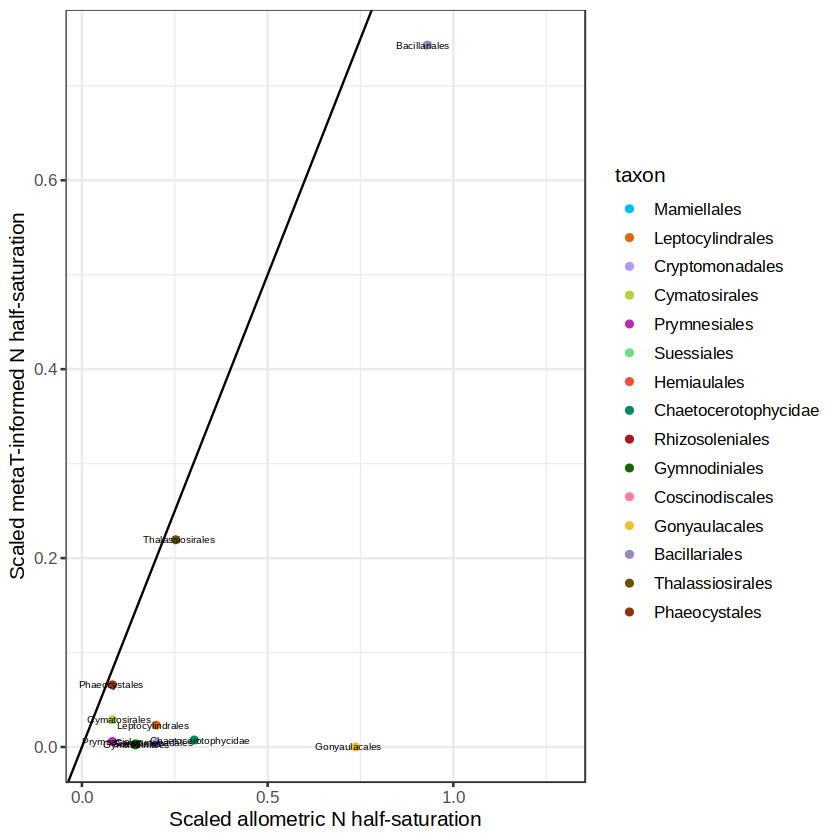

In [61]:
n_half_sat = ggplot(scaling_relationships)+
     geom_abline(aes(intercept=0,
                     slope=1))+
     geom_point(aes(x=half_sat_n/16,
                    y=metaT_n_half_sat/16,
                    color=taxon),show.legend=TRUE)+
     geom_text(aes(x=half_sat_n/16,
                   y=metaT_n_half_sat/16,
                   label=taxon),
               position="jitter",size=2) + 
     theme_bw(base_size=12) +
     scale_color_manual(values=c("#01bdff",
"#dd6800",
"#ae98ff",
"#b1d33c",
"#b92cb2",
"#71dc85",
"#f64f36",
"#008867",
"#a3191e",
"#136600",
"#ff7d9c",
"#f0c033",
"#9888bc",
"#695300",
"#93320e"),breaks=unique(scaling_relationships$taxon),drop = FALSE) + 
    xlab("Scaled allometric N half-saturation")+
    ylab("Scaled metaT-informed N half-saturation")
n_half_sat

In [62]:
p_merge = (n_half_sat | p_half_sat) + plot_layout(guides = "collect")
ggsave("half_sats.png",plot=p_merge,width=10,height=6,units="in")

Warning message:
“Removed 4 rows containing missing values or values outside the scale range
(`geom_point()`).”
Warning message:
“Removed 4 rows containing missing values or values outside the scale range
(`geom_text()`).”


In [64]:
ggsave("half_sats.pdf",plot=p_merge,width=10,height=6,units="in")

Warning message:
“Removed 4 rows containing missing values or values outside the scale range
(`geom_point()`).”
Warning message:
“Removed 4 rows containing missing values or values outside the scale range
(`geom_text()`).”


Warning message:
“Removed 4 rows containing missing values or values outside the scale range
(`geom_point()`).”
Warning message:
“Removed 4 rows containing missing values or values outside the scale range
(`geom_text()`).”


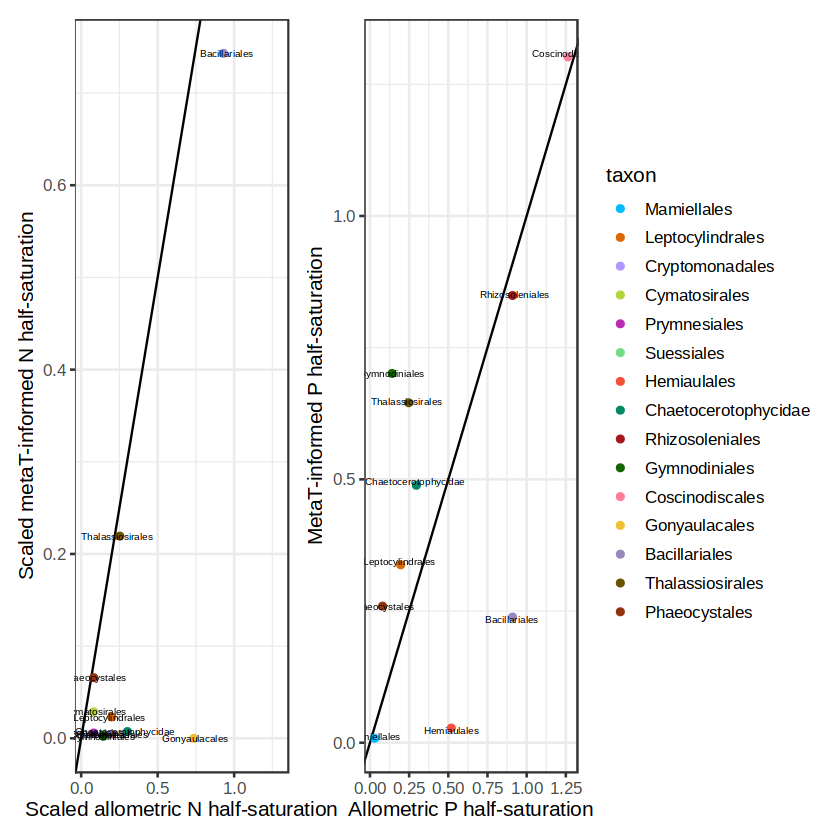

In [63]:
p_merge